# EDA — Sleep Health and Lifestyle Dataset

Exploratory analysis of the public Kaggle dataset that will be used to train the
good/poor sleep classifier.

**Goal of this notebook:**

1. Confirm the dataset loads and has the expected shape.
2. Check for missing values, duplicates, and basic sanity.
3. Create the binary target (`sleep_label`) by thresholding *Quality of Sleep* at 7.
4. Check **class balance** after thresholding — critical for choosing metrics.
5. Confirm the **5 features** that will be shared with the Samsung Health data behave as expected:
   - Sleep Duration
   - Heart Rate
   - Physical Activity Level
   - Stress Level
   - Daily Steps
6. Look at feature distributions by class (good vs poor) to see if the signal is there at all.

**Dataset source:** https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset

Place the CSV at `data/kaggle/Sleep_health_and_lifestyle_dataset.csv` before running.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "kaggle" / "Sleep_health_and_lifestyle_dataset.csv"

print("Looking for dataset at:", DATA_PATH)
print("Exists:", DATA_PATH.exists())

Looking for dataset at: c:\Users\rodri\Documents\sleep-behavior-tracker\data\kaggle\Sleep_health_and_lifestyle_dataset.csv
Exists: True


## 2. Load and overview

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
df.dtypes

Person ID                    int64
Gender                      object
Age                          int64
Occupation                  object
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                object
Blood Pressure              object
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder              object
dtype: object

In [ ]:
#Missing values per column
missing = df.isna().sum()
missing[missing > 0] if missing.sum() > 0 else "No missing values"

Sleep Disorder    219
dtype: int64

In [ ]:
#Duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Person ID,374.0,NaN,NaN,NaN,187.5,108.108742,1.0,94.25,187.5,280.75,374.0
Gender,374,2,Male,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,374.0,NaN,NaN,NaN,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Occupation,374,11,Nurse,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Duration,374.0,NaN,NaN,NaN,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Quality of Sleep,374.0,NaN,NaN,NaN,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0
Physical Activity Level,374.0,NaN,NaN,NaN,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,NaN,NaN,NaN,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
BMI Category,374,4,Normal,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,374,25,130/85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Focus on the 5 classifier features

These are the features that overlap with what the Samsung Galaxy Fit 3 / Samsung Health
export can give us per night. Everything else (demographics, BMI, blood pressure,
occupation) is kept for exploratory purposes but will **not** be used as classifier input.

In [9]:
FEATURES = [
    "Sleep Duration",
    "Heart Rate",
    "Physical Activity Level",
    "Stress Level",
    "Daily Steps",
]
TARGET_RAW = "Quality of Sleep"

#Verify the columns exist with the expected names
for col in FEATURES + [TARGET_RAW]:
    assert col in df.columns, f"Missing column: {col}"
print("All expected columns present.")

All expected columns present.


In [10]:
df[FEATURES + [TARGET_RAW]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sleep Duration,374.0,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Heart Rate,374.0,70.165775,4.135676,65.0,68.0,70.0,72.0,86.0
Physical Activity Level,374.0,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
Daily Steps,374.0,6816.844920,1617.915679,3000.0,5600.0,7000.0,8000.0,10000.0
Quality of Sleep,374.0,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0


## 4. Create the binary target

Following the midterm plan: `sleep_label = 1` (good) if `Quality of Sleep >= 7`, else 0 (poor).

In [11]:
df["sleep_label"] = (df[TARGET_RAW] >= 7).astype(int)

counts = df["sleep_label"].value_counts().sort_index()
pct = (counts / len(df) * 100).round(1)

print("Class balance after thresholding Quality of Sleep >= 7:")
print(pd.DataFrame({"count": counts, "pct": pct}))
print()
print(f"Total rows: {len(df)}")

Class balance after thresholding Quality of Sleep >= 7:
             count   pct
sleep_label             
0              117  31.3
1              257  68.7

Total rows: 374


**What to look for:** heavy imbalance (e.g. 90/10) would mean accuracy alone is a bad
metric and we'd want to lean on F1 and ROC-AUC, and maybe `class_weight="balanced"` in
the Random Forest. Mild imbalance (say 60/40) is fine.

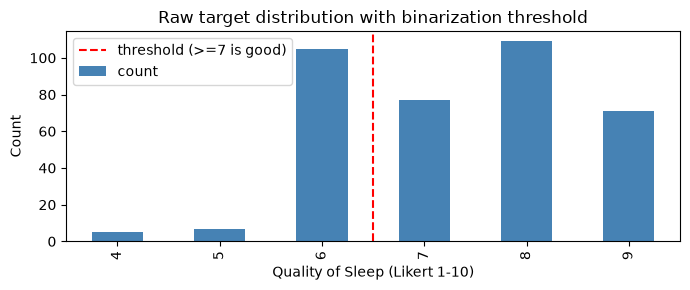

In [12]:
#Also look at the raw Quality of Sleep distribution to see where the threshold cuts
fig, ax = plt.subplots(figsize=(7, 3))
df[TARGET_RAW].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.axvline(x=df[TARGET_RAW].sort_values().unique().tolist().index(7) - 0.5,
           color="red", linestyle="--", label="threshold (>=7 is good)")
ax.set_xlabel("Quality of Sleep (Likert 1-10)")
ax.set_ylabel("Count")
ax.set_title("Raw target distribution with binarization threshold")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Univariate distributions of the 5 features

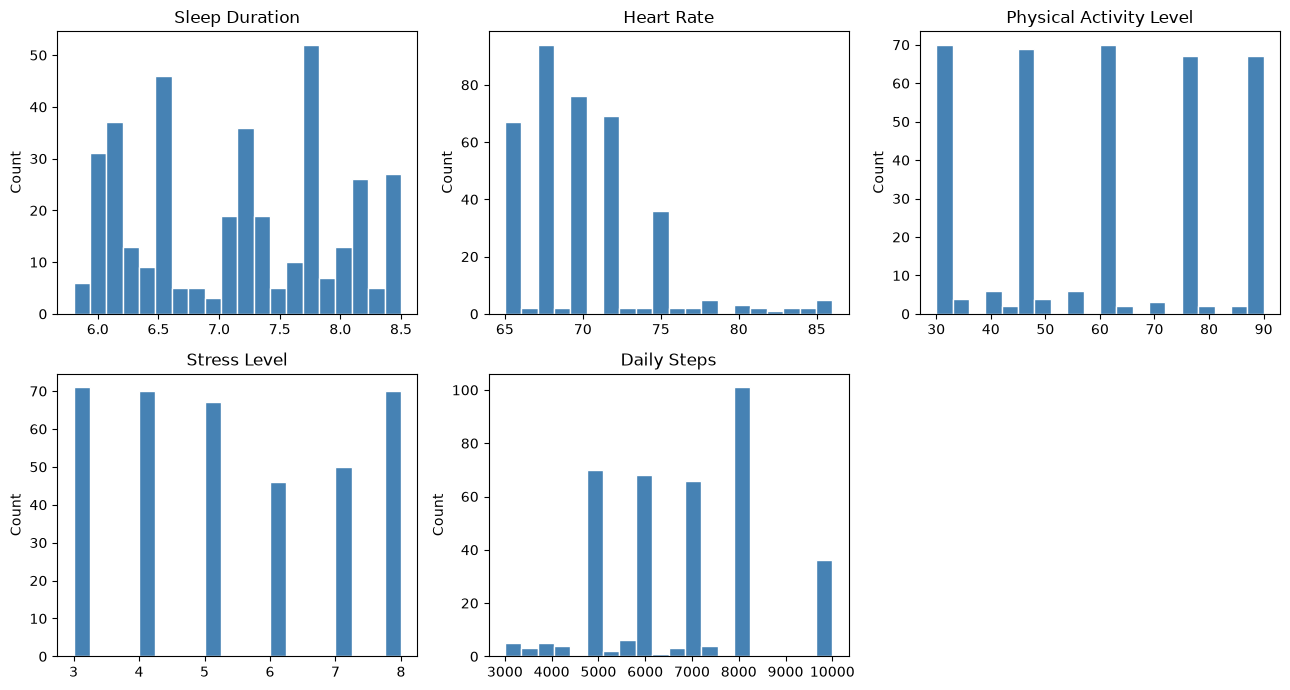

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, feat in enumerate(FEATURES):
    axes[i].hist(df[feat], bins=20, color="steelblue", edgecolor="white")
    axes[i].set_title(feat)
    axes[i].set_ylabel("Count")
axes[-1].axis("off")  #hide the empty subplot
plt.tight_layout()
plt.show()

**Sanity-check these ranges against what the Galaxy Fit 3 can plausibly produce:**

- Sleep Duration: expect ~5-9 hours in the real world.
- Heart Rate: resting HR in adults ~55-90 bpm. If the dataset has values like 65-85, that's consistent.
- Physical Activity Level: Kaggle gives this in minutes/day. Samsung Health has `exercise_time` and `active_time` we'll have to pick one when aligning.
- Stress Level: Likert 1-10 in Kaggle. Samsung Health gives a "stress score" that may use a different scale. Needs mapping.
- Daily Steps: typical range 2k-15k. Fit 3 reports this directly.

**Any obvious bimodality or outlier in these histograms is worth noting now**. It may
point to an issue when we try to apply the model to personal data.

## 6. Feature distributions by class (good vs poor)

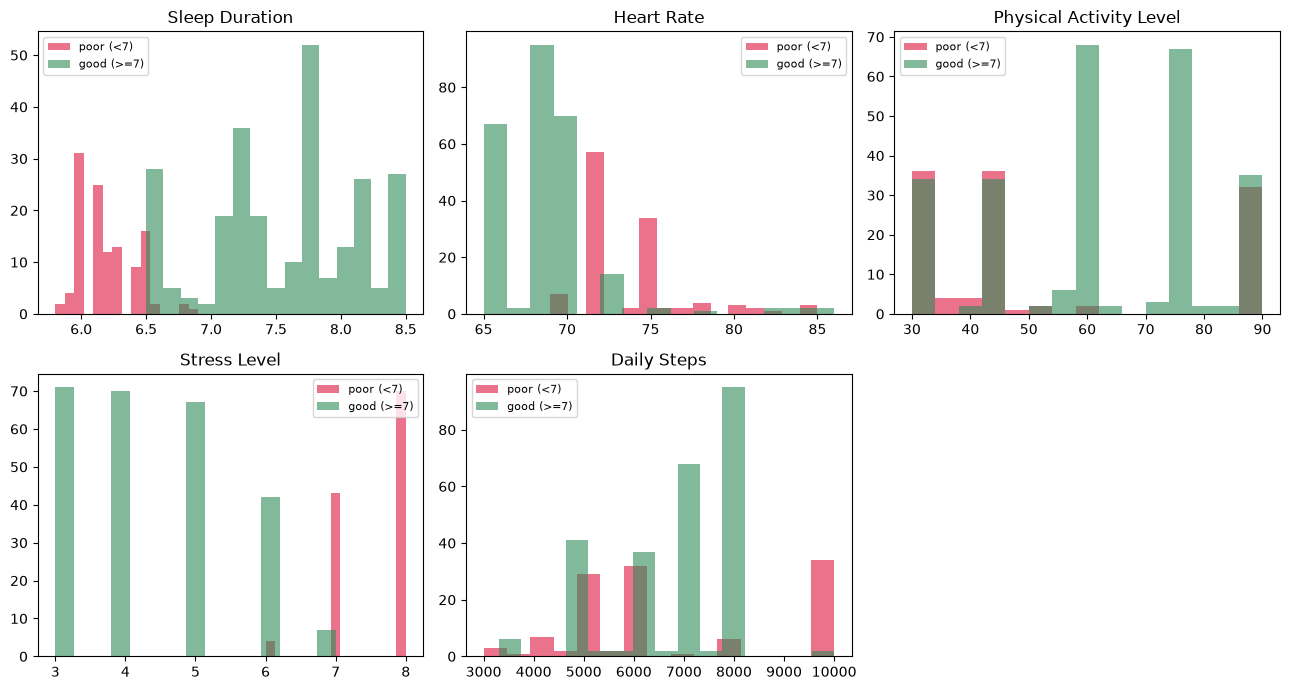

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, feat in enumerate(FEATURES):
    good = df.loc[df["sleep_label"] == 1, feat]
    poor = df.loc[df["sleep_label"] == 0, feat]
    axes[i].hist(poor, bins=15, alpha=0.6, label="poor (<7)", color="crimson")
    axes[i].hist(good, bins=15, alpha=0.6, label="good (>=7)", color="seagreen")
    axes[i].set_title(feat)
    axes[i].legend(fontsize=8)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
#Mean of each feature by class — quick signal check
df.groupby("sleep_label")[FEATURES].mean().T.rename(
    columns={0: "poor (mean)", 1: "good (mean)"}
)

sleep_label,poor (mean),good (mean)
Sleep Duration,6.199145,7.556809
Heart Rate,73.914530,68.459144
Physical Activity Level,52.521368,62.198444
Stress Level,7.564103,4.392996
Daily Steps,6785.470085,6831.128405


**What to look for:** features where the two class distributions are visibly separated
are the ones the classifier can actually use. If a feature's two histograms almost
perfectly overlap, it won't help the model — and that's fine, we have 5 of them.

## 7. Correlations among the 5 features

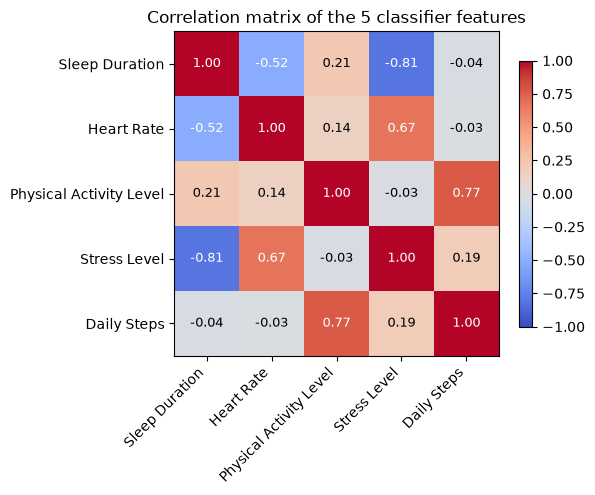

In [16]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.title("Correlation matrix of the 5 classifier features")
plt.tight_layout()
plt.show()

**What to look for:** highly correlated features (|r| > 0.8) are somewhat redundant for
a Random Forest. Not harmful, just means the forest will split on either and feature
importances may be split between them. For logistic regression it can hurt coefficient
interpretability. Worth noting but not a blocker.

In [17]:
#Correlation of each feature with the binary target (point-biserial)
corr_with_target = df[FEATURES + ["sleep_label"]].corr()["sleep_label"].drop("sleep_label")
corr_with_target.sort_values(key=abs, ascending=False).to_frame("corr_with_sleep_label")

,corr_with_sleep_label
Stress Level,-0.829655
Sleep Duration,0.792202
Heart Rate,-0.612418
Physical Activity Level,0.215679
Daily Steps,0.013102


## 9. Findings & notes

- **Dataset size:** 374 rows, 13 columns. Small but workable.
- **Missing values:** none in the 5 features we care about.
- **Duplicates:** 0.
- **Class balance:** 68.7% good (257) vs 31.3% poor (117). Accuracy
  alone can be misleading (a model that always predicts "good" already hits 69%).
  Going to use F1 and ROC-AUC as the main metrics, with accuracy only as a secondary
  reference. Worth trying `class_weight="balanced"` in the Random Forest grid search
  to see if it helps the poor class.
- **Target range:** the raw Quality of Sleep column goes from 4 to 9, not 1 to 10
  like the dataset documentation says. Doesn't change anything for the binary target,
  just something to mention.
- **Which features actually carry signal (correlation with target):**
  - Stress Level: −0.83
  - Sleep Duration: +0.79
  - Heart Rate: −0.61
  - Physical Activity Level: +0.22
  - Daily Steps: +0.01
  
  Daily Steps is basically noise in this dataset. The Random Forest will probably
  ignore it, which is actually convenient. If my phone doesn't track steps perfectly
  during collection, it won't hurt much.
- **Correlations between features worth noting:**
  - Sleep Duration and Stress Level: r = −0.81 (very redundant)
  - Physical Activity and Daily Steps: r = +0.77
  - Heart Rate and Stress Level: r = +0.67
  
  Random Forest handles this fine. For logistic regression the coefficients won't be
  stable, so I'll only use it as a baseline sanity check and not read too much into
  its coefficients.
- **Things that look weird in the Kaggle data:**
  - All the features have those big gaps between peaks (steps clustering at exactly
    5000, 6000, 7000, 8000, etc). Looks like the dataset was generated or aggregated
    by occupation, not from real continuous measurements. My Fit 3 data will be
    continuous (e.g. 7342 steps), so there's a shape mismatch I can't really fix.
  - Stress Level has no values at 1, 2, 9 or 10, even though it's supposed to be 1-10.
  - Heart Rate sits mostly between 65-75 bpm. My average HR is probably in that
    range too, so that part should be fine.
- **What this means for aligning Samsung Health data later:**
  - **Stress is the main concern.** It's the strongest predictor AND the one where
    Samsung measures something very different from Kaggle (HRV score 0-100 vs
    subjective Likert 1-10). The linear rescale from the feature contract is a rough
    workaround; I'll flag this in the final report as a known limitation.
  - **Heart Rate is the second concern.** Kaggle doesn't say if it's resting HR or
    daily average. I'll use daily mean from Samsung and document the choice.
  - **Sleep Duration is the easiest.** Just divide minutes by 60.
  - **Daily Steps barely matters,** so imperfect alignment is OK.
  - **The discreteness problem** (Kaggle values clumped at round numbers, Fit 3 values
    continuous) can't be fixed by StandardScaler. This is a limitation to mention in
    the final report, in line with the "exploratory framing" from the midterm.

These findings will shape the training script (metrics choice, grid search, scaler
inside the pipeline) and the alignment script (extra care with Stress and HR).